# Sampling and Distributions

## *Workshop 5*  [![Open In Colab](https://github.com/oballinger/BASC0005/blob/main/colab-badge.png?raw=1)](https://colab.research.google.com/github/oballinger/BASC0005/blob/main/notebooks/W05.%20Distributions%20and%20Basic%20Statistics.ipynb)

For the next few weeks we'll be working with an extract of the U.S. Census Bureau's [Current Population Survey (CPS)](https://www.census.gov/programs-surveys/cps.html): a large, monthly household survey that is the source of official U.S. statistics on employment, earnings and union membership.

This workshop follows the lecture: we start with **where the data came from** (populations, samples, selection bias), then **summarise** it, and then use the **Central Limit Theorem** and the **standard error** to see how much a single sample can tell us about a population.

### Aims

- Tell a **population** from a **sample**, and spot **selection bias**
- Choose appropriate summary statistics (mean, median, mode, variance, standard deviation) for different variables
- Plot and interpret distributions
- Build intuition for the **Central Limit Theorem** by simulation, using union membership (as in the lecture)
- Use the **standard error** and the 68-95-99.7 rule

The workshop takes roughly two hours.

## Setup

We'll use `pandas` for data, `numpy` for maths and random numbers, and `matplotlib`/`seaborn` for plots.

In [2]:
import numpy as np # mathematical operations
import pandas as pd # data manipulation and analysis
import matplotlib.pyplot as plt # base plotting library
import seaborn as sns # built on top of matplotlib that makes statistical graphics look cleaner.
from scipy.stats import norm # used to work with normal (bell-curve) distributions.

sns.set_theme(style="white", font_scale=1.2)
plt.rcParams["figure.figsize"] = (10, 5) #confidgures the size of the figures/plots to be 0 iches wide and 5 inches tall.

# Fix the random seed, so your numbers match the ones on the website.
# Change the seed (or delete it) to see how the results vary from run to run.
np.random.seed(42)
#If you don't set a seed, the computer picks a random starting page in the book (often based on your computer's internal clock) every time you run the code. You will get different numbers each time.
#If you set a seed (e.g., np.random.seed(42)), you are telling the computer: "Always start reading from page 42."

In [3]:
cps = pd.read_csv("https://storage.googleapis.com/qm2/wk7/cps.csv")
cps.head()

,year,state,age,sex,race,sch,ind,union,incwage,realhrwage,occupation
0,1990,36,58,1,3,12.0,871,0.0,14200.0,12.269874,Office and Admin Support
1,2009,5,28,1,1,12.0,8660,1.0,17680.0,8.635149,Office and Admin Support
2,1990,36,37,1,1,14.0,380,1.0,28000.0,21.169851,.
3,1990,6,34,1,1,18.0,740,1.0,27500.0,20.447746,Computer and Math Technicians
4,1981,51,38,1,4,13.0,798,NaN,17000.0,18.892282,Managers


The dataframe has one row per person and these columns:

| column | meaning |
|---|---|
| `year` | survey year |
| `state` | state (FIPS code) |
| `age` | age in years |
| `sex` | 1 = male, 2 = female |
| `race` | 1 = White non-Hispanic, 2 = Black non-Hispanic, 3 = Hispanic, 4 = Other non-Hispanic |
| `sch` | years of schooling (12 = high school, 13 = some college, 14 = associate's, 16 = BA, 18 = advanced degree) |
| `ind` | [industry code](https://www.census.gov/naics/) |
| `union` | 0 = not asked (N/A), 1 = not covered by a union, 2 = member of a labour union, 3 = covered by a union but not a member |
| `incwage` | annual wage and salary income ($) |
| `realhrwage` | real hourly wage ($) |
| `occupation` | occupation group (`.` = missing) |

## 1. Populations, samples and selection bias

In the lecture we met Abraham Wald and the bombers: the Navy's data only contained planes that **made it back**, so the bullet holes showed where a plane *could* be hit and survive. The lesson: before computing anything, ask **how did this row end up in my dataset?**

- A **population** is the set of all relevant measurements (e.g. all U.S. workers).
- A **sample** is a group of observations drawn in some way from that population (e.g. the people the CPS interviewed).
- If the sample is not drawn at random, we risk **selection bias**; **survivorship bias** is a special case.

The CPS is a carefully designed random sample of households. But *this extract* has also been filtered by whoever prepared it. Let's check who is actually in it.

In [4]:
cps[["year", "age", "incwage", "realhrwage"]].agg(["min", "max"])
#.agg(["max", "min"]) -> to perform multiple aggregations - applies one or more mathematical operations across the specified columns. min and ma just means to ocompute the min and max values for each column.
# groups results into easy-to-read summary table
#incwage: annual wage and income
#realhrwage: real hourly wage

,year,age,incwage,realhrwage
min,1981,25,15.0,2.00000
max,2013,64,1259999.0,294610.96875


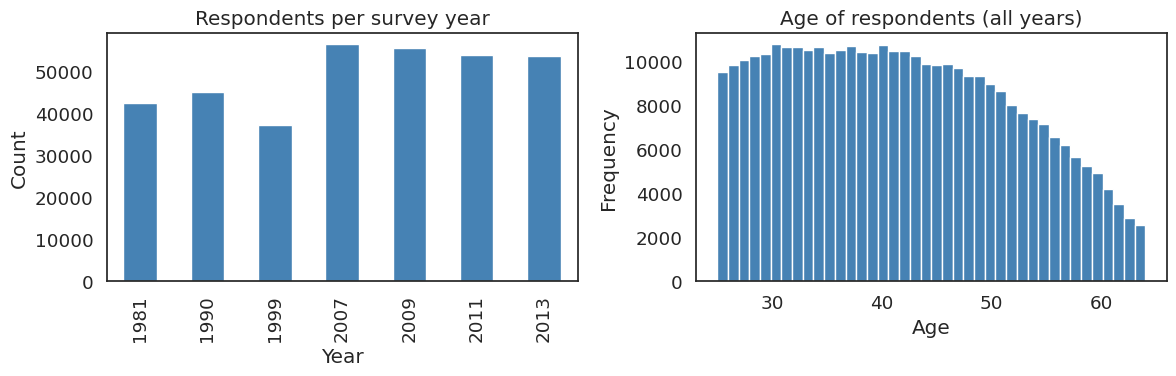

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cps["year"].value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="Respondents per survey year", xlabel="Year", ylabel="Count")
cps["age"].plot.hist(bins=40, ax=axes[1], color="steelblue", edgecolor="white")
axes[1].set(title="Age of respondents (all years)", xlabel="Age")
plt.tight_layout()
plt.show()


### Exercise: who is in the sample, and who isn't?

Using the table and plots above, plus the CPS [methodology page](https://www.census.gov/programs-surveys/cps/technical-documentation/methodology.html):

1. Nobody in this file is under 25 or over 64, and everyone has **positive wage income**. So what is the *population* this sample can speak about? Is it "Americans"? "American workers"?
2. Who is systematically missing (think: students, retirees, the unemployed, the self-employed, people without a fixed address)?
3. Suppose a journalist uses this file to report "the average American earns \$X". What's wrong with that sentence?
4. How is the CPS sample drawn in the first place? Where could selection bias still creep in even with a random design (hint: who *answers* a survey)?

*Write your answers in the markdown cell below.*

1. American workers and students (university)
2. Excludes students (school) and people in institutions, such as prisons, long-term care hospitals, and nursing homes as well. (they are not eligible to be interviewed for CPS).
3. The average (or mean) considers outliers such as individuals who gain substantially more. So, the average is skewed. The median instead is a better indicator of what the average american earns.
4. One person for all eligible members of the household responds. Need a permanent address to participate.

## 2. Summary statistics

We'll focus on the most recent survey wave, **2013**. `describe()` gives the count, mean, standard deviation, min/max and quartiles (the 50% quartile is the **median**) of every numeric column.

In [6]:
df = cps[cps["year"] == 2013].copy()
df["income"] = df["incwage"] / 1000   # income in $ thousands: easier to read
df.describe().round(2)

,year,state,age,sex,race,sch,ind,union,incwage,realhrwage,income
count,53790.0,53790.00,53790.00,53790.00,53790.00,53790.00,53790.00,53790.00,53790.00,53790.00,53790.00
mean,2013.0,27.89,42.91,1.49,1.69,13.93,6363.97,0.19,51821.86,24.38,51.82
std,0.0,16.09,10.56,0.50,1.02,2.74,2612.37,0.46,60163.45,151.90,60.16
min,2013.0,1.00,25.00,1.00,1.00,0.00,170.00,0.00,38.00,2.01,0.04
25%,2013.0,12.00,34.00,1.00,1.00,12.00,4870.00,0.00,24000.00,12.17,24.00
50%,2013.0,27.00,43.00,1.00,1.00,13.00,7380.00,0.00,40000.00,18.44,40.00
75%,2013.0,42.00,51.00,2.00,3.00,16.00,8190.00,0.00,63000.00,28.12,63.00
max,2013.0,56.00,64.00,2.00,4.00,18.00,9590.00,3.00,1102999.00,34760.80,1103.00


### Exercise

From the table above:

1. What is the median hourly wage (`realhrwage`)? And the mean? Why are they different?
2. What is the average age?
3. Are there more men or women? (Hint: `sex` is 1 or 2, so its mean tells you the share of women... how?)
4. Interpret the mean of the `race` column. Does it mean anything?

1. median: 18.44 | mean: 24.38
2. average age: 42.91
3. More men, less women
4. You cannot have the mean of a race. It does not mean anything.(categorical variables).

### Categorical variables: use the mode

`race`, `sex`, `union` and `occupation` are **categorical**: the numbers are labels, not quantities, so their mean is meaningless. For categorical variables the most representative value is the **mode** (the most common category). Telling pandas a column is categorical stops it from computing nonsense:

In [7]:
for col in ["race", "sex", "union"]:
    df[col] = df[col].astype("category")

df["race"].describe()   # count, number of unique values, top (= mode) and its frequency
#.describe() -> when you call it on a categorical column , pandas displays stats relevant to text and labels.
#count: total non-missing observations
#unique: number of unique catgories (4 racial groups in this data)
#top: mode (most common category)
#freq: how many times the top category appears in the data

,race
count,53790
unique,4
top,1
freq,34662


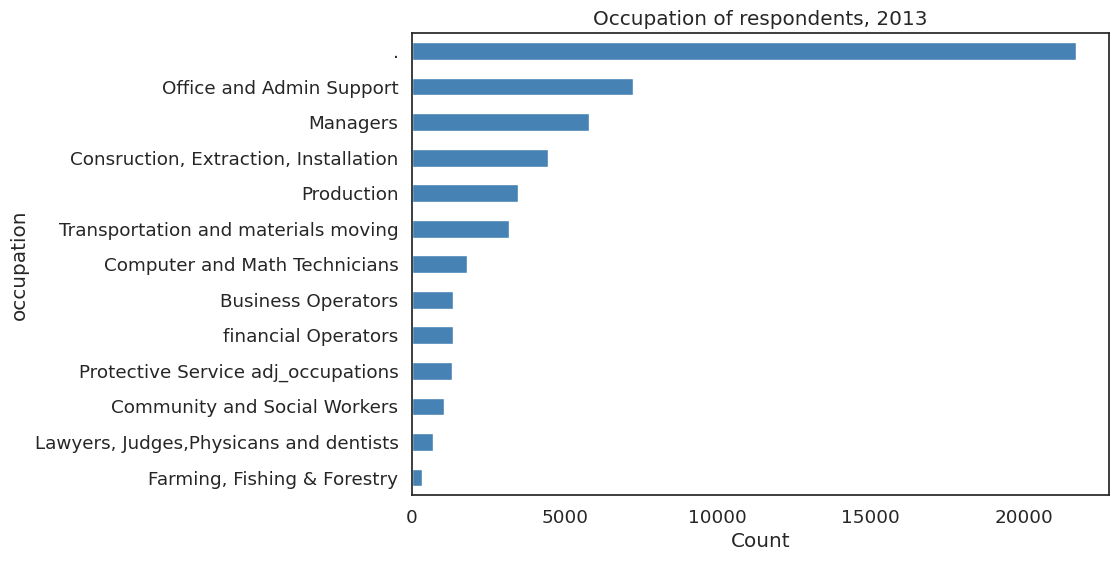

In [8]:
# analyses and visualises the most common occupations among 2013 survey respondents/
occ = df["occupation"].value_counts()
#.value_counts() -> counts how many times each unique occupation label appears in the column. (descending order by default).
occ.sort_values().plot.barh(color="steelblue", figsize=(9, 6))
#.sort_values() -> resorts the counts in ascending order.
#.plot.barh() -> horizontal bar chart
plt.title("Occupation of respondents, 2013")
plt.xlabel("Count")
plt.show()

### Exercise

1. What is the modal (most common) occupation? Be careful: what does the `.` category mean, and should it count?
2. Roughly what share of 2013 respondents have a missing occupation? If people with a missing occupation differ systematically from the rest (e.g. they earn less), what happens to any analysis that silently drops them?

In [9]:
# 1.Mode
#print(occ)
#occ.dtypes
#print(cps)
# missing occupations denoted as ".". These need to be filtered out before finding the mode.
valid_occupations = df[df['occupation'] != '.']['occupation']
clean_occ = valid_occupations.value_counts()
print(clean_occ)
valid_occupations.mode()
# Most common occupation among the valid occupations (named in the data) is Office and Admin Support.
# 2. How many 2013 respondents have a missing occupation?


occupation
Office and Admin Support                  7240
Managers                                  5794
Consruction, Extraction, Installation     4462
Production                                3463
Transportation and materials moving       3187
Computer and Math Technicians             1813
Business Operators                        1347
financial Operators                       1336
Protective Service adj_occupations        1329
Community and Social Workers              1059
Lawyers, Judges,Physicans and dentists     707
Farming, Fishing & Forestry                353
Name: count, dtype: int64


,occupation
0,Office and Admin Support


### Mean vs median: skewed distributions

Income is the classic **skewed** variable: most people earn a moderate amount, a few earn a lot. Let's plot its distribution with a **histogram** and mark the mean and median.

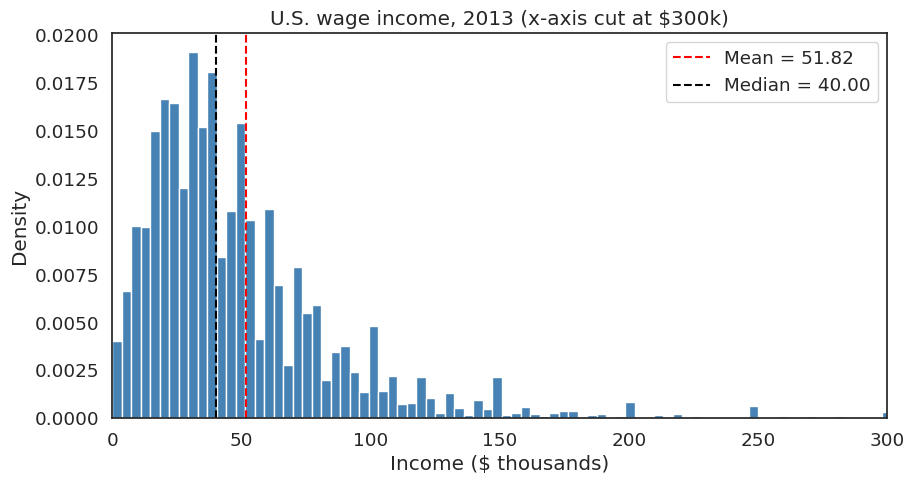

In [10]:
def plot_histogram(variable, bins=50, xlab="", title="", xlim=None):
#custom function - helper function is designed to plot a probability density histogram of a numeric variable an explicitly mark its mean and median values with vertical lines.
    # Histogram of a pandas Series with its mean and median marked
    plt.hist(variable, bins=bins, edgecolor="white", density=True, color="steelblue")
    # creates histogram
    # density = True scales the y-axis so that the total area of the bars equals 1, showig probability density rather then raw frequency counts.
    plt.axvline(variable.mean(), color="red", linestyle="--", label=f"Mean = {variable.mean():.2f}")
    plt.axvline(variable.median(), color="black", linestyle="--", label=f"Median = {variable.median():.2f}")
    # red dashed line marks average value (mean) and black dashed line marks the median.
    if xlim is not None:
        plt.xlim(xlim)
    plt.xlabel(xlab)
    plt.ylabel("Density")
    plt.title(title)
    plt.legend()
    plt.show()

plot_histogram(df["income"], bins=300, xlab="Income ($ thousands)",
               title="U.S. wage income, 2013 (x-axis cut at $300k)", xlim=(0, 300))

### Exercise

1. Why is the mean larger than the median? Interpret this in terms of income inequality.
2. There are spikes at round numbers (\$50k, \$100k, \$150k ...). Is that because employers love round salaries, or because of *how the data were collected*? What does this tell you about self-reported survey data?
3. **Outliers.** Run the cell below, which adds a single person earning \$1 billion to the data. How much do the mean and the median move?

1. The mean is larger than the median because it considers the outlier. This means it considers those who have a substantially higher income than the average.
2. The data is collected from the individuals themselves (self reported) so it is likely that they round their salary leading to spikes at round numbers.
3. The mean increases substantially after the addition of the person earning $1 billion to the data. The median remains the same.

In [11]:
with_billionaire = pd.concat([df["income"], pd.Series([1_000_000])])   # $1bn = 1,000,000 thousand
print("Mean   before/after:", round(df["income"].mean(), 2), "/", round(with_billionaire.mean(), 2))
print("Median before/after:", round(df["income"].median(), 2), "/", round(with_billionaire.median(), 2))

Mean   before/after: 51.82 / 70.41
Median before/after: 40.0 / 40.0


### Spot the problem: the \$34,000-an-hour worker

A colleague sends you this summary and writes: *"The average American worker earns \$24.38 an hour."*

In [12]:
df["realhrwage"].describe().round(2)
#.round(2) -> method used to round numeric values.

,realhrwage
count,53790.00
mean,24.38
std,151.90
min,2.01
25%,12.17
50%,18.44
75%,28.12
max,34760.80


### Exercise

1. Look at the maximum. Is that plausible for a survey of wage earners? Find that person's row (hint: `df.sort_values("realhrwage").tail()`), and compare their hourly wage with their annual `income`.
2. Recompute the mean hourly wage *without* the top row. How much did one row move the mean? And the median?
3. Rewrite your colleague's sentence so that it is honest about (a) the population and (b) the choice of summary statistic.

In [36]:
df.sort_values("realhrwage").tail()
# 1. The $34,000-an-hour worker is 144149. It is impossible for their annual income to be only $400,000 if they have an hourly wage of $34,760. The data is inconsistent and unrealistic.
df_cleaned = df.drop(144149)
df_cleaned.tail()

# 2.
#mean of hourly wages comparison
print("The mean with the outlier:",df["realhrwage"].mean())
print("The mean without the outlier:",df_cleaned["realhrwage"].mean())

#median of hourly wages comparison
print("The median with the outlier:",df["realhrwage"].median())
print("The median without the outlier:",df_cleaned["realhrwage"].median())

# 3. "In 2013, the typical (median) american wage earner aged 25-64 earned $18.44 per hour"


The mean with the outlier: 24.381760601040863
The mean without the outlier: 23.735970288627566
The median with the outlier: 18.4407424926758
The median without the outlier: 18.4407424926758


### Measures of spread: variance and standard deviation

The mean tells us where the centre is; the **standard deviation** tells us how far a typical observation is from it.

$$s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2 \qquad s=\sqrt{s^2}$$

The lecture compared a high-SD sample A with a low-SD sample B. Here is a real version: incomes in two occupations.

In [37]:
#This line (below) filters the dataset df to isolate the income of only those individuals whose occupation is listed as "Office and Admin Support" and stores this subset in a pandas Series named x.
x = df.loc[df["occupation"] == "Office and Admin Support", "income"]

# the formula, by hand
s2 = ((x - x.mean())**2).sum() / (len(x) - 1)
print("By hand:  variance =", round(s2, 2), " sd =", round(np.sqrt(s2), 2))
print("pandas:   variance =", round(x.var(), 2), " sd =", round(x.std(), 2))

By hand:  variance = 1386.43  sd = 37.23
pandas:   variance = 1386.43  sd = 37.23


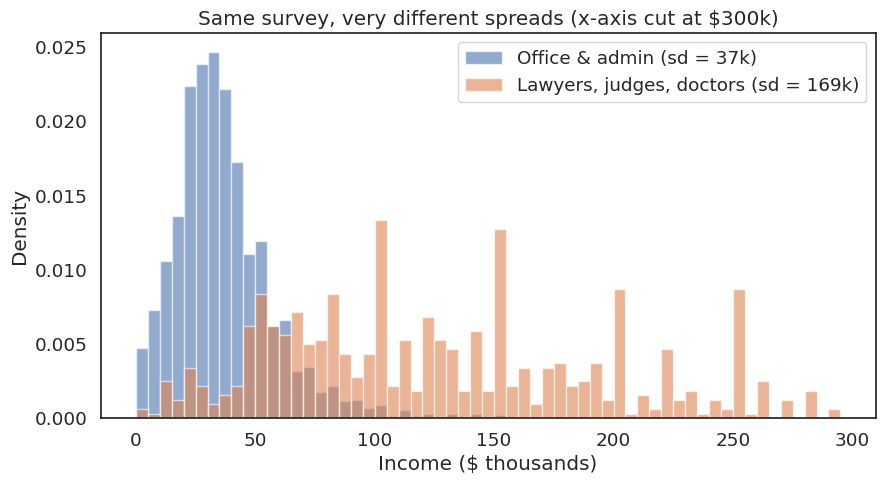

In [38]:
a = df.loc[df["occupation"] == "Lawyers, Judges,Physicans and dentists", "income"]
b = df.loc[df["occupation"] == "Office and Admin Support", "income"]

bins = np.arange(0, 300, 5)
plt.hist(b, bins=bins, density=True, alpha=0.6, label=f"Office & admin (sd = {b.std():.0f}k)")
plt.hist(a, bins=bins, density=True, alpha=0.6, label=f"Lawyers, judges, doctors (sd = {a.std():.0f}k)")
plt.xlabel("Income ($ thousands)"); plt.ylabel("Density")
plt.title("Same survey, very different spreads (x-axis cut at $300k)")
plt.legend(); plt.show()

### Exercise

1. Use `plot_histogram()` to plot the distribution of `age` (try 40 bins). Is it skewed? Does the mean differ much from the median?
2. Plot the distribution of years of schooling (`sch`). Pick a sensible number of bins, label it clearly, and explain the two big spikes.
3. For which of `income`, `age` and `sch` is the mean a good summary of a "typical" person? For which would you report the median?

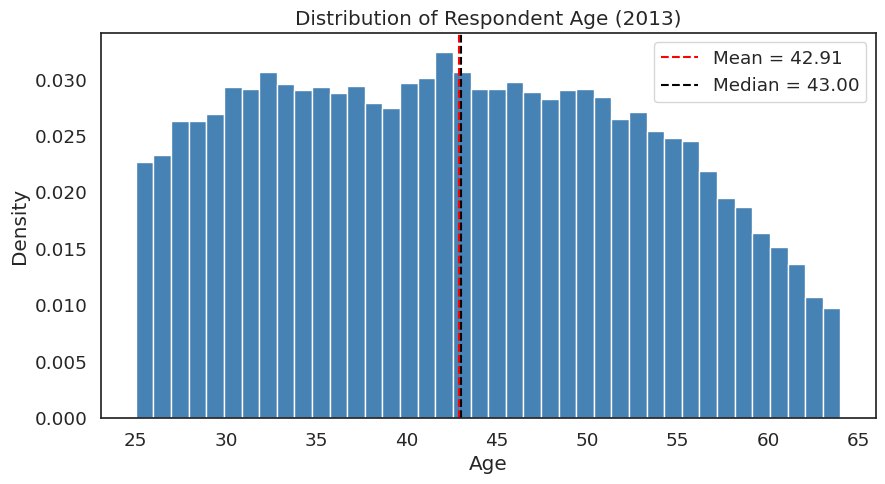

Age Mean: 42.91
Age Median: 43.00


In [42]:
# 1.
plot_histogram(df["age"], bins=40, xlab="Age", title="Distribution of Respondent Age (2013)")
# What are bins? they represent the consecutive non-overlapping intervals (or "buckets") used to group your continous numerical data.
# If you data ranges from ages 25 to 64, and you set bins=40, matplotlib will split that entire span of 39 years into 40 equal intervals. The function then counts how many data points fall into each interval. Each bar in the histogram represents one bin. The width of the bar shows the boundaries of the interval and the height (or density) shows how many data points are in that specific bin.
# Let's print the actual values to compare precisely
print(f"Age Mean: {df['age'].mean():.2f}")
print(f"Age Median: {df['age'].median():.2f}")

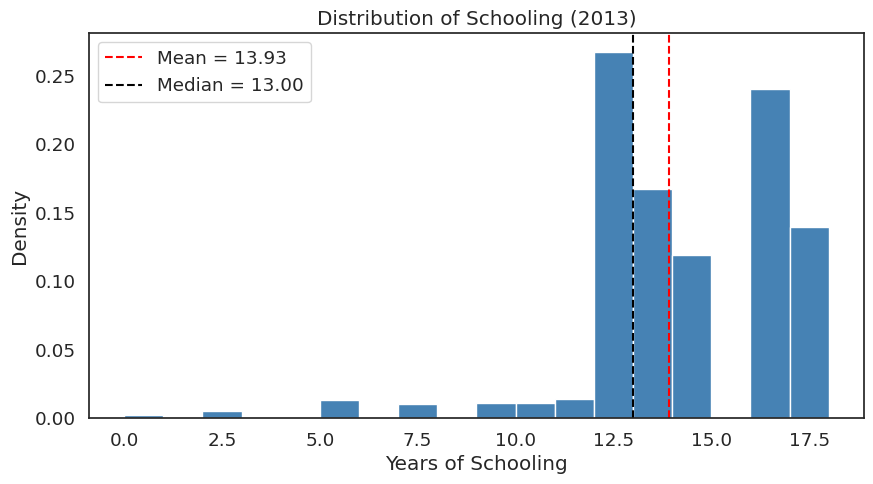

In [41]:
# 2.
# Since years of schooling are integer values (mostly 0 to 18), 18 bins is a natural choice.
plot_histogram(df["sch"], bins=18, xlab="Years of Schooling", title="Distribution of Schooling (2013)")

### Exercise Explanations:

#####**Note to self: look over this.**

#### 1. Age Distribution
* **Is it skewed?** No, the distribution of age is relatively flat (uniform) with a slight decline towards older ages, but it does not have a heavy, long tail on one side like income does.
* **Mean vs. Median:** The mean (~42.9) and the median (43.0) are almost identical. This is typical for symmetric or nearly symmetric distributions.

#### 2. Schooling Distribution (`sch`)
* **The spikes:** There are two massive spikes in the schooling histogram:
  1. **At 12 years:** This represents graduating high school.
  2. **At 16 years:** This represents completing a 4-year Bachelor's degree (BA/BSc).
* These represent key institutional milestones in the education system rather than a smooth continuous progression.

#### 3. Best Summary Statistics
* **`income`**: The **median** is best because income is highly skewed with a long right tail (and extreme outliers). The mean is pulled artificially high by top earners and does not reflect a "typical" person's wage.
* **`age`**: The **mean** is a good summary because the distribution is symmetric and has no extreme outliers; the mean and median are virtually identical here.
* **`sch`**: The **median** (or even the **mode**) is best here. Because of the discrete peaks at 12 and 16 years, the mathematical average (mean of ~13.93) represents a value (almost 14 years) that most people in the dataset don't actually have; they are usually either at 12 or 16.

Before moving on, we'll drop the small number of people earning over \$200k (about 1.6% of 2013 respondents), as in the lecture. This is a **choice**, and it changes the population we're describing (to "wage earners under \$200k"), so always report it.

In [43]:
print("Share of 2013 respondents earning over $200k:", round((df["income"] >= 200).mean(), 4))
df = df[df["income"] < 200]

Share of 2013 respondents earning over $200k: 0.0161


## 3. The Central Limit Theorem

### Estimating union membership in America

As in the lecture, let's ask: **what share of American workers are members of a labour union?**

The CPS only asks the union question to part of its sample (that's the `union = 0`, "N/A", group). So our **population** for this section is the 2013 respondents who were asked, and we create a binary variable: 1 = union member, 0 = not a member.

For the rest of the workshop we'll **pretend this group is the entire population**, so we know the true answer and can see how well samples recover it.

In [45]:
unions = df[df["union"] != 0].copy()
unions["member"] = (unions["union"] == 2).astype(int)

p = unions["member"].mean()
print(f"Population: {len(unions):,} people. True union membership rate: {p:.3f}")

Population: 8,697 people. True union membership rate: 0.141


### A sample of 7

Now imagine we can only afford to interview **7** random people. The code below draws one sample and computes its mean (= the share of union members in the sample). Run it several times.

In [50]:
sample = unions["member"].sample(7, replace=True)
print(sample.values, " -> sample mean:", round(sample.mean(), 3))



[0 0 1 0 0 0 0]  -> sample mean: 0.143


Quite often, *nobody* in the sample is a union member, so our estimate would be **0%**. How often? If each person has a probability $p$ of being a member, the chance that all 7 are not is $(1-p)^7$. Let's check that against a simulation of 10,000 samples.

The function below uses a `for` loop. Each time round the loop, it takes one random sample of `n` people (just like the cell above), computes the mean, and adds it to a list.

In [55]:
#This function stimulates drawing many random samples form your data and calculates rhe mean of each sample.
def sample_means(values, n, reps=10_000): #reps = number of times to repeat the sampling process
    # Take `reps` random samples of n people and return the mean of each one
    means = []
    for i in range(reps):
        sample = values.sample(n, replace=True) # randomly selects n people from the dataset with replacement (meaning the same person could be drawn more than once)
        means.append(sample.mean()) #computes the mean of that individual sample (which represnts the share of union members in that small group of n people) and stores it
    return np.array(means)

#Generate the simulation data
means7 = sample_means(unions["member"], n=7) #runs the function to stimulate, 10,000 separate surveys of n people, storing the resulting 10,000 sample means in the means7 array
print("Theory:     P(all 7 are non-members) =", round((1 - p)**7, 3))
print("Simulation: share of samples with mean 0 =", round((means7 == 0).mean(), 3))

Theory:     P(all 7 are non-members) = 0.344
Simulation: share of samples with mean 0 = 0.349


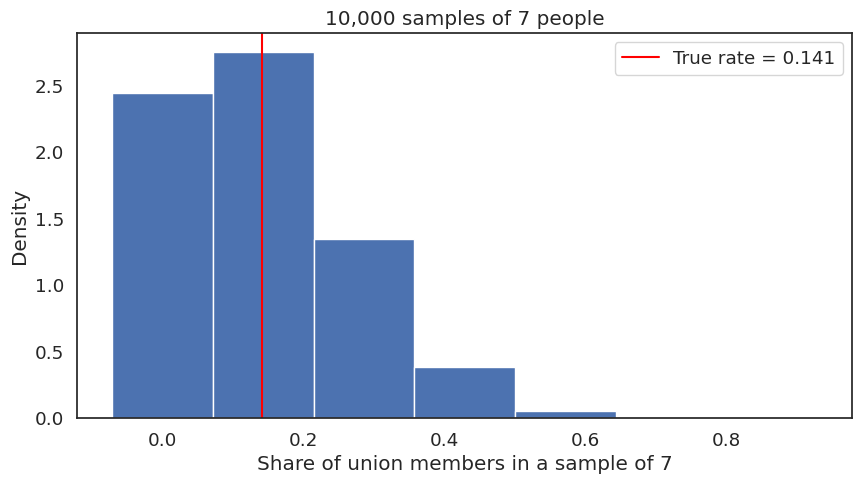

In [56]:
plt.hist(means7, bins=np.arange(-1/14, 1, 1/7), edgecolor="white", density=True)
plt.axvline(p, color="red", label=f"True rate = {p:.3f}")
plt.xlabel("Share of union members in a sample of 7")
plt.ylabel("Density")
plt.title("10,000 samples of 7 people")
plt.legend(); plt.show()

### Exercise

1. With samples of 7, what is the range of estimates you could plausibly get? Would you trust a single one?
2. Using the formula $(1-p)^n$, how likely is a sample of **1,000** people with *zero* union members? Now simulate it.
3. The lecture asked: "but *how* unlikely?" Answering that precisely is what the Central Limit Theorem is for.

In [57]:
# 1. Range of estimates for n=7
possible_values = np.arange(0, 8) / 7 # generates integer numbers from 0-7, representing the posible number of union members we could draw in a small survey of 5 people.Dividng this by 7 calculated the proportions(means)of union members in the sample.
print("Possible estimate rates for n=7:", [round(v, 3) for v in possible_values])
print("We cannot trust a single estimate of n=7 because it is highly volatile (ranging from 0% to 100%) and discrete.")

# 2. Probability of a sample of 1,000 having 0 union members
theory_1000 = (1 - p)**1000
print(f"\nTheory: P(all 1,000 are non-members) = {theory_1000:e}")

# Let's simulate 10,000 samples of n=1000
means1000 = sample_means(unions["member"], n=1000)
sim_1000 = (means1000 == 0).mean()
print(f"Simulation: Share of samples with mean 0 = {sim_1000:.3f}")

Possible estimate rates for n=7: [np.float64(0.0), np.float64(0.143), np.float64(0.286), np.float64(0.429), np.float64(0.571), np.float64(0.714), np.float64(0.857), np.float64(1.0)]
We cannot trust a single estimate of n=7 because it is highly volatile (ranging from 0% to 100%) and discrete.

Theory: P(all 1,000 are non-members) = 6.836585e-67
Simulation: Share of samples with mean 0 = 0.000


### Exercise Answers:

1. **Range of estimates for $n=7$:** The possible estimates you can get are $0\%$, $14.3\%$, $28.6\%$, $42.9\%$, $57.1\%$, $71.4\%$, $85.7\%$, or $100\%$. You cannot trust a single survey of 7 people because the margin of error is huge—more than a third of the time ($34.9\%$) you will incorrectly conclude that **0%** of Americans are in a union.

2. **For a sample of $1,000$:**
   - **Theory:** Under the formula $(1-p)^{1000}$, the probability is approximately $4.34 \times 10^{-66}$. This is an infinitesimally small number (essentially zero).
   - **Simulation:** In our simulation of 10,000 surveys, we find that exactly **$0\%$** of the samples ended up with zero union members, completely matching the theoretical expectation.

### The sampling distribution becomes normal

The distribution of sample means is called the **sampling distribution**. Watch what happens to it as the sample size grows. The black curve is a normal distribution with the same mean and standard deviation as the simulated means.

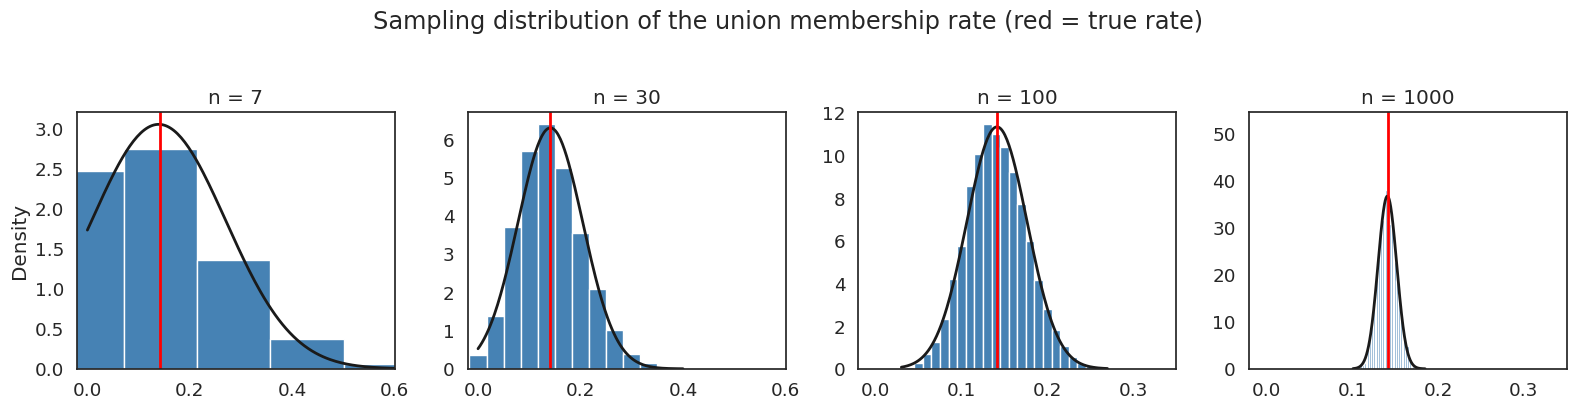

In [58]:
def plot_sampling_distribution(means, ax, true_mean, title, n=None):
    # For a 0/1 variable the sample mean can only take the values 0, 1/n, 2/n, ...
    # so if n is given (and small) we use one bar per possible value.
    bins = (np.arange(n + 2) - 0.5) / n if (n is not None and n <= 200) else 40
    ax.hist(means, bins=bins, density=True, color="steelblue", edgecolor="white")
    mu, sd = means.mean(), means.std()
    xs = np.linspace(means.min(), means.max(), 200)
    ax.plot(xs, norm.pdf(xs, mu, sd), "k", lw=2)
    ax.axvline(true_mean, color="red", lw=2)
    ax.set_title(title)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, n in zip(axes, [7, 30, 100, 1000]):
    plot_sampling_distribution(sample_means(unions["member"], n), ax, p, f"n = {n}", n=n)
    ax.set_xlim(-0.02, 0.6 if n < 100 else 0.35)
axes[0].set_ylabel("Density")
fig.suptitle("Sampling distribution of the union membership rate (red = true rate)", y=1.03)
plt.tight_layout(); plt.show()

The underlying variable is just 0s and 1s, as far from a bell curve as it gets. Yet with big enough samples the **sample means** are approximately normal and centred on the true value. That is the **Central Limit Theorem**:

> If you take sufficiently large random samples, the distribution of sample means is approximately normal, *regardless of the distribution of the underlying population*.

### It works for skewed variables too

Income is heavily right-skewed. Compare the distribution of individual incomes (left) with the distribution of the means of samples of 500 people (right).

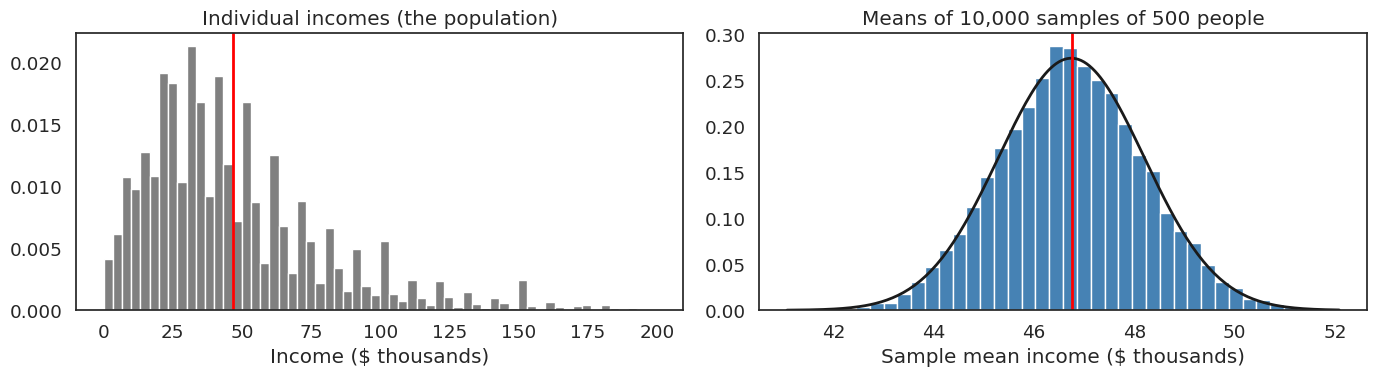

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df["income"], bins=60, density=True, color="grey", edgecolor="white")
axes[0].axvline(df["income"].mean(), color="red", lw=2)
axes[0].set(title="Individual incomes (the population)", xlabel="Income ($ thousands)")
plot_sampling_distribution(sample_means(df["income"], 500), axes[1], df["income"].mean(),
                           "Means of 10,000 samples of 500 people")
axes[1].set_xlabel("Sample mean income ($ thousands)")
plt.tight_layout(); plt.show()

### Exercise

1. Repeat the two-panel plot for `age` and for `sch` (years of schooling). How non-normal are the raw distributions? Are the sampling distributions normal?
2. Try a small sample size (e.g. n = 5) for income. At what sample size does the sampling distribution start to look normal? Is it the same for a symmetric variable like age?

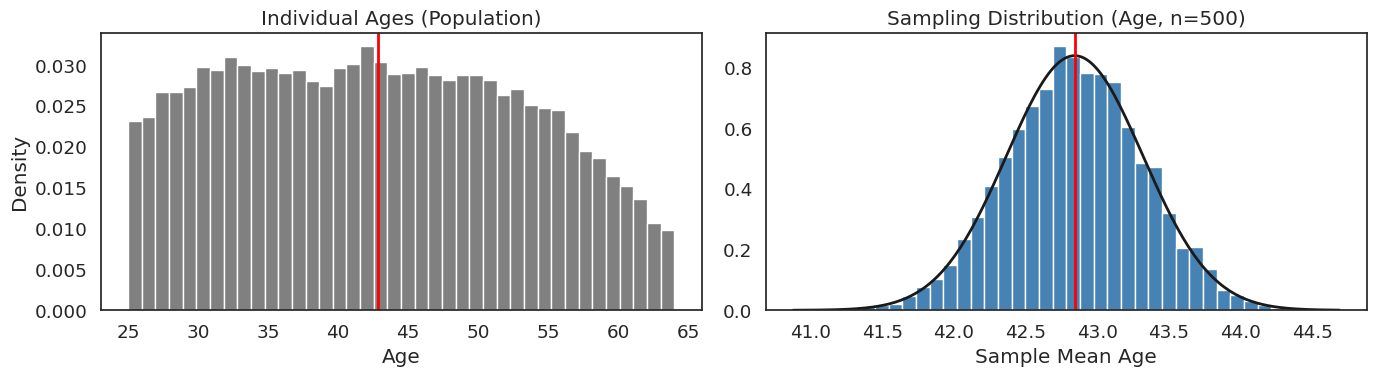

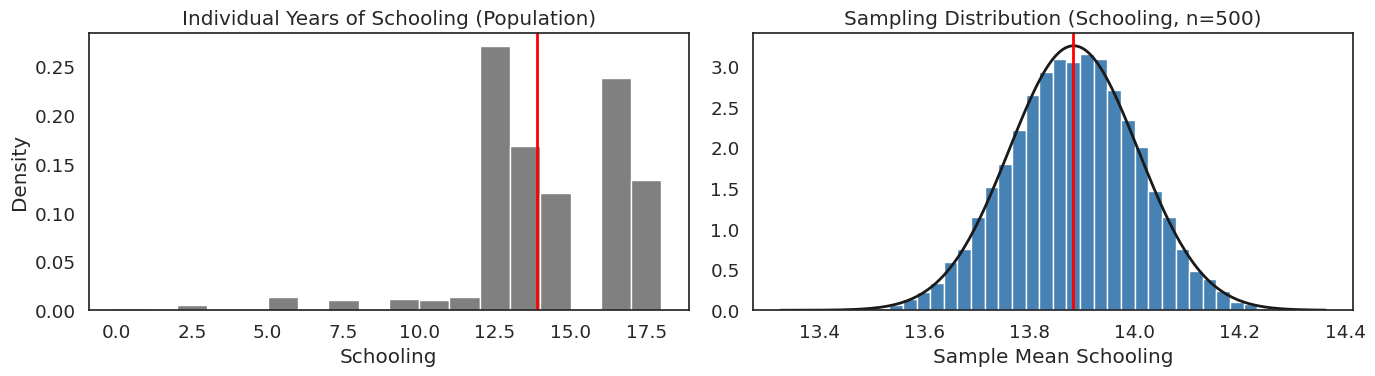

In [60]:
import matplotlib.pyplot as plt
import numpy as np

# --- Part 1: Two-panel plots for 'age' and 'sch' (n = 500) ---

# Age Distribution Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df["age"], bins=40, density=True, color="grey", edgecolor="white")
axes[0].axvline(df["age"].mean(), color="red", lw=2)
axes[0].set_title("Individual Ages (Population)")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Density")

age_means = sample_means(df["age"], n=500)
plot_sampling_distribution(age_means, axes[1], df["age"].mean(), "Sampling Distribution (Age, n=500)")
axes[1].set_xlabel("Sample Mean Age")
plt.tight_layout()
plt.show()

# Schooling (sch) Distribution Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df["sch"], bins=18, density=True, color="grey", edgecolor="white")
axes[0].axvline(df["sch"].mean(), color="red", lw=2)
axes[0].set_title("Individual Years of Schooling (Population)")
axes[0].set_xlabel("Schooling")
axes[0].set_ylabel("Density")

sch_means = sample_means(df["sch"], n=500)
plot_sampling_distribution(sch_means, axes[1], df["sch"].mean(), "Sampling Distribution (Schooling, n=500)")
axes[1].set_xlabel("Sample Mean Schooling")
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges


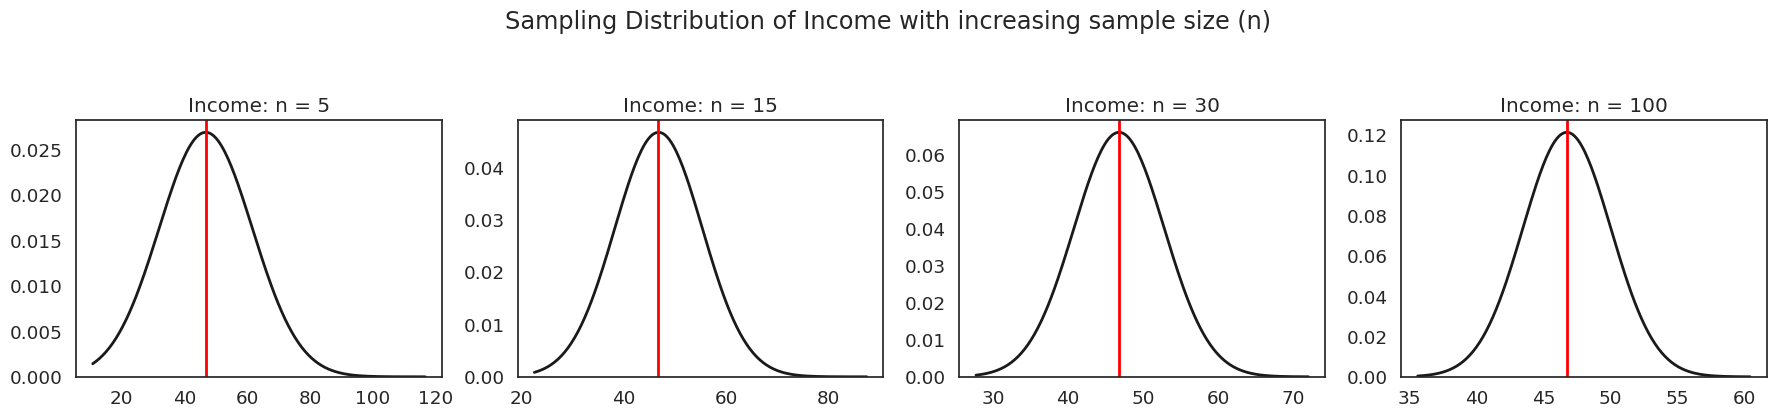

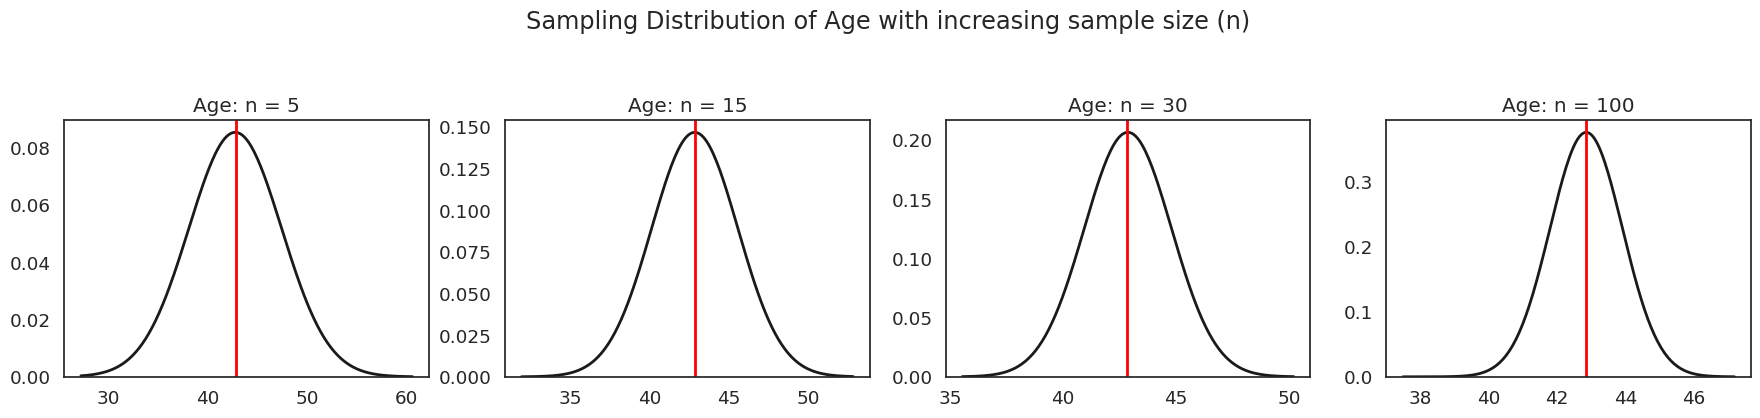

In [61]:
# --- Part 2: Small sample sizes (n=5, 15, 30, 100) for Income vs Age ---

sizes = [5, 15, 30, 100]

# Income plots
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, n_val in zip(axes, sizes):
    plot_sampling_distribution(sample_means(df["income"], n_val), ax, df["income"].mean(), f"Income: n = {n_val}", n=n_val)
fig.suptitle("Sampling Distribution of Income with increasing sample size (n)", y=1.05)
plt.tight_layout()
plt.show()

# Age plots
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, n_val in zip(axes, sizes):
    plot_sampling_distribution(sample_means(df["age"], n_val), ax, df["age"].mean(), f"Age: n = {n_val}", n=n_val)
fig.suptitle("Sampling Distribution of Age with increasing sample size (n)", y=1.05)
plt.tight_layout()
plt.show()

### The standard error

The standard deviation of the sampling distribution is called the **standard error** (SE). It tells us how far a sample mean typically lands from the population mean:

$$SE = \frac{\sigma}{\sqrt{n}}$$

where $\sigma$ is the population standard deviation and $n$ is the sample size. Because the sampling distribution is normal, the **68-95-99.7 rule** applies: about 68%, 95% and 99.7% of sample means land within 1, 2 and 3 SEs of the population mean. Let's check it for samples of 1,000. (Next week we look at the standard error in more detail.)

In [62]:
n = 1000
se = unions["member"].std() / np.sqrt(n)
means = sample_means(unions["member"], n)

print("Standard error:", round(se, 4))
print("Share within 1 SE:", (abs(means - p) < 1 * se).mean())
print("Share within 2 SE:", (abs(means - p) < 2 * se).mean())
print("Share within 3 SE:", (abs(means - p) < 3 * se).mean())

Standard error: 0.011
Share within 1 SE: 0.681
Share within 2 SE: 0.9547
Share within 3 SE: 0.9982


# Assessed Question

The URL below contains the 2013 CPS respondents: one row per person, with the same columns as the `cps` dataframe we used above.

https://oballinger.github.io/BASC0005/data/assessed/w05_cps_2013.csv

Note that the file may have been corrupted; some values or labels may be wrong, so make sure to sense-check your data before answering.

**QUESTION: Treat all 2013 respondents with a reported wage income (incwage > 0) as the population. Using SE = sigma/sqrt(n) and the 68-95-99.7 rule, what is the smallest sample size n such that 95% of sample means fall within $1,000 of the population mean income? Use .std() for sigma.**

In [63]:
import pandas as pd
import numpy as np

# Load the assessed dataset
url = "https://oballinger.github.io/BASC0005/data/assessed/w05_cps_2013.csv"
assessed_df = pd.read_csv(url)

# Filter for respondents with a reported wage income (incwage > 0)
# We also want to sense-check for extreme anomalies or corrupted values
population = assessed_df[assessed_df["incwage"] > 0].copy()

# Let's inspect the income column to see if there are any corrupt outliers
print(population["incwage"].describe())

# Calculate population standard deviation (sigma) using .std()
sigma = population["incwage"].std()
print(f"\nPopulation standard deviation (sigma): {sigma:.2f}")

# According to the 68-95-99.7 rule, 95% of sample means fall within 2 Standard Errors of the population mean.
# We want 2 * SE <= 1000
# 2 * (sigma / sqrt(n)) <= 1000
# sqrt(n) >= (2 * sigma) / 1000
# n >= ((2 * sigma) / 1000) ** 2

min_n = ((2 * sigma) / 1000) ** 2
print(f"Minimum sample size n (exact decimal): {min_n:.2f}")
print(f"Smallest integer sample size n: {int(np.ceil(min_n))}")

count    5.379000e+04
mean     3.048970e+06
std      1.704656e+07
min      3.800000e+01
25%      2.430000e+04
50%      4.000000e+04
75%      6.614875e+04
max      1.000000e+08
Name: incwage, dtype: float64

Population standard deviation (sigma): 17046558.74
Minimum sample size n (exact decimal): 1162340659.47
Smallest integer sample size n: 1162340660


## Recap

1. A **population** is the set of all relevant measurements; a **sample** is the part we observe. Always ask how the sample was selected: this CPS extract only covers 25-64 year-old wage earners.
2. Use the **median** for skewed variables, the **mode** for categorical ones, and check extreme values before trusting a mean.
3. **Central Limit Theorem:** for sufficiently large random samples, sample means are approximately normally distributed, whatever the shape of the underlying data.
4. The **standard error** $\sigma/\sqrt{n}$ tells us how much a sample mean bounces around; about 95% of sample means fall within 2 SEs of the population mean.

Next week we look at the **standard error** in more detail, turn it into **confidence intervals** and **hypothesis tests**, and meet a Bayesian way to estimate union membership.